In [17]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier  #평균절대값오차
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import Ridge

In [18]:
## 다중회귀 - 특성이 여러 개일 때
df = pd.read_csv('data/perch_full.csv')
df.head(3)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00
2,15.0,3.82,2.43


In [19]:
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [20]:
# 학습데이터 / 테스트 데이터 분리
train_data,test_data,train_label,test_label = train_test_split(df,perch_weight,random_state=42)

In [50]:
poly = PolynomialFeatures(degree=4,include_bias=False)  #include_bias=False 학습의미없는 데이터 1를 생략
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
train_poly[:2]

array([[1.96000000e+01, 5.14000000e+00, 3.04000000e+00, 3.84160000e+02,
        1.00744000e+02, 5.95840000e+01, 2.64196000e+01, 1.56256000e+01,
        9.24160000e+00, 7.52953600e+03, 1.97458240e+03, 1.16784640e+03,
        5.17824160e+02, 3.06261760e+02, 1.81135360e+02, 1.35796744e+02,
        8.03155840e+01, 4.75018240e+01, 2.80944640e+01, 1.47578906e+05,
        3.87018150e+04, 2.28897894e+04, 1.01493535e+04, 6.00273050e+03,
        3.55025306e+03, 2.66161618e+03, 1.57418545e+03, 9.31035750e+02,
        5.50651494e+02, 6.97995264e+02, 4.12822102e+02, 2.44159375e+02,
        1.44405545e+02, 8.54071706e+01],
       [2.20000000e+01, 5.88000000e+00, 3.52000000e+00, 4.84000000e+02,
        1.29360000e+02, 7.74400000e+01, 3.45744000e+01, 2.06976000e+01,
        1.23904000e+01, 1.06480000e+04, 2.84592000e+03, 1.70368000e+03,
        7.60636800e+02, 4.55347200e+02, 2.72588800e+02, 2.03297472e+02,
        1.21701888e+02, 7.28555520e+01, 4.36142080e+01, 2.34256000e+05,
        6.26102400e+04,

In [51]:
# 1차원
lr = LinearRegression()
lr.fit(train_data, train_label)
predict = lr.predict(test_data)
print('무게 예측: ', predict)

score = lr.score(train_data, train_label)
score2 = lr.score(test_data, test_label)
print(f'정확도:{score*100}%, {score2*100}%')

무게 예측:  [-322.78309496   52.96101903  329.77783424  171.46884473  149.65836217
  789.639144    383.68482432  250.05247716  813.2470793   126.13660027
  980.20626415  -33.35965799  357.76466578  421.8675313 ]
정확도:95.59326821885706%, 87.96419177546366%


In [52]:
# 2차원
lr = LinearRegression()
lr.fit(train_poly, train_label)
predict = lr.predict(test_poly)
print('무게 예측: ', predict)

score = lr.score(train_poly, train_label)
score2 = lr.score(test_poly, test_label)
print(f'정확도:{score*100}%, {score2*100}%')

무게 예측:  [  27.6526997    61.33148601  255.5563934   126.29512923  135.28727748
  780.45784191  336.71746318  180.46622142  875.77899089  101.55406992
 1168.8311871    51.08787117  256.16201835  273.36562632]
정확도:99.50570894726734%, 97.55705435112506%


In [53]:
# StandartScaler
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [54]:
alpha_list = [0.001,0.01,0.1,1,10,100]
train_score = []
test_score = []

for alpha in alpha_list:

    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    score = ridge.score(train_scaled, train_label)
    score2 = ridge.score(test_scaled, test_label)
    train_score.append(score)
    test_score.append(score2)
print(f'정확도:{score*100}%, {score2*100}%')


정확도:98.4189961737136%, 97.82834538876887%


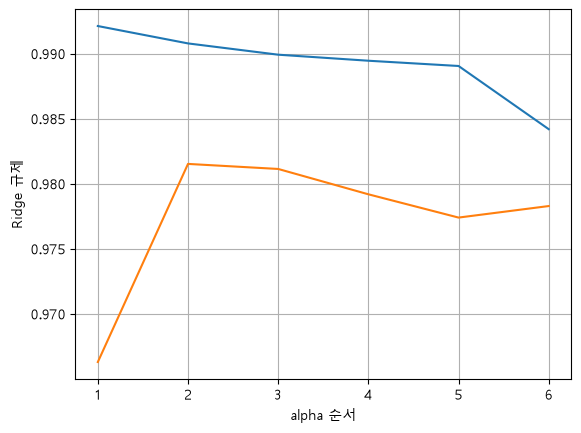

In [56]:
# 그래프 그리기
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.grid()
plt.xlabel('alpha 순서')
plt.ylabel('Ridge 규제')
plt.show()